# 23CSE301 ML Capstone — EV Charging Station Opportunity Analysis

## Problem Statement

The growth of electric vehicles requires sufficient and well-distributed EV charging infrastructure. However, choosing where to add a new charging station is difficult because existing stations, location, infrastructure availability, accessibility, network information, and station characteristics must be considered.

This project uses machine learning on EV charging-station data to:
1. **Predict a continuous Opportunity Score** for a station location using regression algorithms.
2. **Classify Profit Potential** into **Low, Medium, or High** using classification algorithms.
3. Compare multiple machine-learning algorithms using appropriate evaluation metrics.
4. Use the results to support data-driven analysis of potential EV charging-station opportunities.

> **Important:** The ML models do not use `Nearest_Station_Distance_km`, `Competition_Level`, or `Opportunity_Score` as classification predictors because these fields are directly related to the target and would cause target leakage.

## Target Variables

### Regression Target — `Opportunity_Score`

`Opportunity_Score` is a **continuous numerical target from 0 to 100**.

- It is derived from the nearest-station distance using percentile ranking.
- A **higher score** represents a location that is farther from existing stations and therefore has a higher calculated opportunity.
- Regression models predict the numerical Opportunity Score.

### Classification Target — `Profit_Potential`

`Profit_Potential` is a **categorical target** with three classes:

- **Low** — lower calculated opportunity because the location is close to existing stations.
- **Medium** — moderate calculated opportunity.
- **High** — higher calculated opportunity because the location is farther from existing stations.

Classification models predict one of these three classes.

## Notebook Structure

1. **Dataset Understanding**
2. **Preprocessing**
3. **REGRESSIONS — 10 Algorithms**
4. **CLASSIFICATION — 5 Algorithms**
5. **Model Comparison**
6. **ML Confidence Score**


## 0. Imports and Configuration

In [2]:
%pip install jupyter notebook matplotlib numpy pandas seaborn scikit-learn openpyxl
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.decomposition import PCA

from sklearn.linear_model import (
    LinearRegression, Ridge, Lasso, ElasticNet, LogisticRegression
)
from sklearn.preprocessing import PolynomialFeatures
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR, SVC
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    r2_score, mean_squared_error, mean_absolute_error,
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, roc_auc_score,
    classification_report, ConfusionMatrixDisplay
)

RANDOM_STATE = 42
TEST_SIZE = 0.20

DATA_PATH = "EV_Charging_Profit_Classification_Raw_with_Opportunity_Score.xlsx"

REG_TARGET = "Opportunity_Score"
CLF_TARGET = "Profit_Potential"

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

Note: you may need to restart the kernel to use updated packages.


## 1. Dataset Understanding

In [3]:
df = pd.read_excel(DATA_PATH)

print("Shape:", df.shape)
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

display(df.head())

Shape: (65134, 23)
Rows: 65134
Columns: 23


,Station Name,City,State,ZIP,Status Code,EV Level1 EVSE Num,EV Level2 EVSE Num,EV DC Fast Count,EV Network,EV Connector Types,Latitude,Longitude,Owner Type Code,Open Date,Facility Type,EV Pricing,Restricted Access,EV Workplace Charging,Access Code,Nearest_Station_Distance_km,Competition_Level,Profit_Potential,Opportunity_Score
0,LADWP - Truesdale Center,Sun Valley,CA,91352,E,NaN,57.0,2.0,SHELL_RECHARGE,CHADEMO J1772 J1772COMBO,34.248319,-118.387971,LG,36448.0,UTILITY,NaN,NaN,1.0,private,0.738,Low,High,79.46
1,Los Angeles Convention Center,Los Angeles,CA,90015,E,NaN,7.0,NaN,Non-Networked,J1772,34.040539,-118.271387,P,34941.0,PARKING_GARAGE,Free; parking fee,0.0,0.0,public,0.287,Medium,Medium,66.09
2,LADWP - John Ferraro Building,Los Angeles,CA,90012,E,NaN,338.0,12.0,Non-Networked,CHADEMO J1772 J1772COMBO,34.059133,-118.248589,LG,36448.0,UTILITY,NaN,NaN,1.0,private,0.000,High,Low,2.35
3,LADWP - Haynes Power Plant,Long Beach,CA,90803,E,NaN,19.0,1.0,Non-Networked,CHADEMO J1772 J1772COMBO,33.759802,-118.096665,LG,43221.0,UTILITY,NaN,NaN,1.0,private,1.032,Low,High,83.53
4,LADWP - Harbor Generating Station,Wilmington,CA,90744,E,NaN,10.0,NaN,Non-Networked,J1772,33.770508,-118.265628,LG,36448.0,UTILITY,NaN,NaN,1.0,private,0.278,Medium,Medium,65.67


### 1.1 Structure and data types

In [4]:
structure = pd.DataFrame({
    "Column": df.columns,
    "Data Type": df.dtypes.astype(str).values,
    "Non-Null": df.notna().sum().values,
    "Null": df.isna().sum().values,
    "Unique Values": df.nunique(dropna=True).values
})

display(structure)

numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numeric columns:", len(numeric_cols))
print("Categorical columns:", len(categorical_cols))

,Column,Data Type,Non-Null,Null,Unique Values
0,Station Name,object,65133,1,62509
1,City,object,65129,5,6494
2,State,object,65120,14,52
3,ZIP,object,65133,1,11104
4,Status Code,object,65134,0,1
5,EV Level1 EVSE Num,float64,667,64467,37
6,EV Level2 EVSE Num,float64,56677,8457,73
7,EV DC Fast Count,float64,9364,55770,43
8,EV Network,object,65132,2,45
9,EV Connector Types,object,65098,36,28


Numeric columns: 10
Categorical columns: 13


### 1.2 Basic checks

In [5]:
print("Duplicate rows:", df.duplicated().sum())

print("\nMissing values:")
display(
    df.isna().sum()
    .sort_values(ascending=False)
    .to_frame("Missing Count")
)

print("\nNumeric summary:")
display(df[numeric_cols].describe().T)

print("\nRegression target:", REG_TARGET)
display(pd.to_numeric(df[REG_TARGET], errors="coerce").describe())

print("\nClassification target:", CLF_TARGET)
display(df[CLF_TARGET].value_counts(dropna=False))

Duplicate rows: 13

Missing values:


,Missing Count
EV Level1 EVSE Num,64467
EV DC Fast Count,55770
Restricted Access,54603
EV Pricing,52174
Facility Type,47537
Owner Type Code,46768
EV Level2 EVSE Num,8457
Open Date,79
EV Connector Types,36
State,14



Numeric summary:


,count,mean,std,min,25%,50%,75%,max
EV Level1 EVSE Num,667.0,4.379310,8.532664,1.000000,1.000000,2.000000,4.000000,90.000000
EV Level2 EVSE Num,56677.0,2.420382,3.273703,1.000000,2.000000,2.000000,2.000000,338.000000
EV DC Fast Count,9364.0,4.206002,5.058703,1.000000,1.000000,2.000000,6.000000,84.000000
Latitude,65134.0,37.816967,5.040287,-41.354100,34.040619,38.503573,41.488183,64.852466
Longitude,65134.0,-96.670801,19.528462,-164.848855,-117.927948,-92.807549,-78.963729,122.373276
Open Date,65055.0,44093.412728,1084.487782,34941.000000,43819.000000,44265.000000,44848.000000,45536.000000
Restricted Access,10531.0,0.108442,0.310952,0.000000,0.000000,0.000000,0.000000,1.000000
EV Workplace Charging,65133.0,0.021341,0.144519,0.000000,0.000000,0.000000,0.000000,1.000000
Nearest_Station_Distance_km,65134.0,1.317836,35.114911,0.000000,0.006000,0.077000,0.537000,6629.882000
Opportunity_Score,65134.0,50.000339,28.860299,2.350000,26.980000,50.020000,74.990000,100.000000



Regression target: Opportunity_Score


count    65134.000000
mean        50.000339
std         28.860299
min          2.350000
25%         26.980000
50%         50.020000
75%         74.990000
max        100.000000
Name: Opportunity_Score, dtype: float64


Classification target: Profit_Potential


Profit_Potential
Low       21713
High      21711
Medium    21710
Name: count, dtype: int64

## 2. Preprocessing

### Targets used in this project

- **Regression:** `Opportunity_Score` — continuous 0–100 score.
- **Classification:** `Profit_Potential` — `Low`, `Medium`, `High`.

### Preprocessing order
1. Remove exact duplicates
2. Remove rows with missing target
3. Feature engineering
4. Select useful predictors and avoid target leakage
5. Train/test split
6. Detect numeric outliers using **IQR**
7. Cap outliers using training-derived IQR limits
8. Fill numeric missing values using **KNN Imputer**
9. Fill categorical missing values
10. **One-Hot Encode** categorical variables
11. **Standardize** features
12. Apply **PCA** for dimensionality reduction

> Preprocessing is fitted on the training data only to avoid data leakage.


### 2.1 Basic cleaning and feature engineering

In [6]:
data = df.copy()

before = len(data)
data = data.drop_duplicates().copy()
print("Duplicates removed:", before - len(data))

if "Open Date" in data.columns:
    open_date = pd.to_datetime(
        data["Open Date"],
        unit="D",
        origin="1899-12-30",
        errors="coerce"
    )
    data["Open Year"] = open_date.dt.year
    data["Station Age"] = 2024 - data["Open Year"]

if "EV Connector Types" in data.columns:
    data["Num Connector Types"] = (
        data["EV Connector Types"]
        .fillna("")
        .astype(str)
        .str.strip()
        .apply(lambda x: 0 if not x else len(set(x.split())))
    )

if "EV Network" in data.columns:
    data["Is Networked"] = (
        data["EV Network"]
        .fillna("Non-Networked")
        .astype(str)
        .str.lower()
        .ne("non-networked")
        .astype(int)
    )

if "EV Pricing" in data.columns:
    data["Has Pricing"] = data["EV Pricing"].notna().astype(int)

if "EV Workplace Charging" in data.columns:
    data["Has Workplace Charging"] = (
        pd.to_numeric(
            data["EV Workplace Charging"],
            errors="coerce"
        ).fillna(0) > 0
    ).astype(int)

print("Shape after cleaning:", data.shape)

Duplicates removed: 13
Shape after cleaning: (65121, 29)


### 2.2 Feature selection

In [7]:
reg_features = [
    c for c in [
        "Latitude", "Longitude", "Open Year", "Station Age",
        "Num Connector Types", "Is Networked", "Has Pricing",
        "Has Workplace Charging", "Access Code", "State",
        "Facility Type", "EV Network"
    ]
    if c in data.columns and c not in {
        REG_TARGET, "EV Level1 EVSE Num", "EV DC Fast Count"
    }
]

clf_features = [
    c for c in [
        "Latitude",
        "Longitude",
        "Open Year",
        "Station Age",
        "Num Connector Types",
        "Is Networked",
        "Has Pricing",
        "Has Workplace Charging",
        "EV Level1 EVSE Num",
        "EV Level2 EVSE Num",
        "EV DC Fast Count",
        "State",
        "EV Network",
        "Facility Type",
        "Owner Type Code",
        "Access Code",
        "Status Code",
        "Restricted Access"
    ]
    if c in data.columns and c not in {
        CLF_TARGET,
        "Nearest_Station_Distance_km",
        "Competition_Level",
        "Opportunity_Score"
    }
]

print("Regression features:")
print(reg_features)

print("\nClassification features:")
print(clf_features)

print("\nClassification target-leakage fields excluded:")
print([
    "Nearest_Station_Distance_km",
    "Competition_Level",
    "Opportunity_Score"
])

Regression features:
['Latitude', 'Longitude', 'Open Year', 'Station Age', 'Num Connector Types', 'Is Networked', 'Has Pricing', 'Has Workplace Charging', 'Access Code', 'State', 'Facility Type', 'EV Network']

Classification features:
['Latitude', 'Longitude', 'Open Year', 'Station Age', 'Num Connector Types', 'Is Networked', 'Has Pricing', 'Has Workplace Charging', 'EV Level1 EVSE Num', 'EV Level2 EVSE Num', 'EV DC Fast Count', 'State', 'EV Network', 'Facility Type', 'Owner Type Code', 'Access Code', 'Status Code', 'Restricted Access']

Classification target-leakage fields excluded:
['Nearest_Station_Distance_km', 'Competition_Level', 'Opportunity_Score']


### 2.3 Train/test split

In [8]:
reg_df = data[reg_features + [REG_TARGET]].copy()
reg_df[REG_TARGET] = pd.to_numeric(
    reg_df[REG_TARGET],
    errors="coerce"
)
reg_df = reg_df.dropna(subset=[REG_TARGET])

X_reg = reg_df[reg_features]
y_reg = reg_df[REG_TARGET]

X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_reg,
    y_reg,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE
)

clf_df = data[clf_features + [CLF_TARGET]].dropna(
    subset=[CLF_TARGET]
).copy()

X_clf = clf_df[clf_features]
y_clf = clf_df[CLF_TARGET].astype(str)

X_clf_train, X_clf_test, y_clf_train, y_clf_test = train_test_split(
    X_clf,
    y_clf,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y_clf
)

print("Regression:", X_reg_train.shape, X_reg_test.shape)
print("Classification:", X_clf_train.shape, X_clf_test.shape)

Regression: (52096, 12) (13025, 12)
Classification: (52096, 18) (13025, 18)


### 2.4 Outlier detection — IQR

**IQR = Q3 − Q1**

Potential outlier = value `< Q1 − 1.5×IQR` or `> Q3 + 1.5×IQR`.

In [9]:
def iqr_report(X, numeric_columns):
    rows = []

    for col in numeric_columns:
        s = pd.to_numeric(X[col], errors="coerce")
        q1, q3 = s.quantile([0.25, 0.75])
        iqr = q3 - q1
        low = q1 - 1.5 * iqr
        high = q3 + 1.5 * iqr
        count = ((s < low) | (s > high)).sum()

        rows.append({
            "Feature": col,
            "Q1": q1,
            "Q3": q3,
            "IQR": iqr,
            "Lower Bound": low,
            "Upper Bound": high,
            "Outliers": int(count)
        })

    return pd.DataFrame(rows)

reg_num = X_reg_train.select_dtypes(
    include=np.number
).columns.tolist()

clf_num = X_clf_train.select_dtypes(
    include=np.number
).columns.tolist()

print("Regression outliers")
display(iqr_report(X_reg_train, reg_num))

print("Classification outliers")
display(iqr_report(X_clf_train, clf_num))

Regression outliers


,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outliers
0,Latitude,34.039189,41.482642,7.443453,22.874009,52.647822,372
1,Longitude,-117.964957,-78.980559,38.984399,-176.441555,-20.503961,7
2,Open Year,2019.000000,2022.000000,3.000000,2014.500000,2026.500000,3319
3,Station Age,2.000000,5.000000,3.000000,-2.500000,9.500000,3319
4,Num Connector Types,1.000000,1.000000,0.000000,1.000000,1.000000,6618
5,Is Networked,1.000000,1.000000,0.000000,1.000000,1.000000,7333
6,Has Pricing,0.000000,0.000000,0.000000,0.000000,0.000000,10381
7,Has Workplace Charging,0.000000,0.000000,0.000000,0.000000,0.000000,1131


Classification outliers


,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outliers
0,Latitude,34.030670,41.469460,7.438790,22.872484,52.627645,383
1,Longitude,-117.926814,-78.957632,38.969182,-176.380587,-20.503858,7
2,Open Year,2019.000000,2022.000000,3.000000,2014.500000,2026.500000,3314
3,Station Age,2.000000,5.000000,3.000000,-2.500000,9.500000,3314
4,Num Connector Types,1.000000,1.000000,0.000000,1.000000,1.000000,6588
5,Is Networked,1.000000,1.000000,0.000000,1.000000,1.000000,7386
6,Has Pricing,0.000000,0.000000,0.000000,0.000000,0.000000,10377
7,Has Workplace Charging,0.000000,0.000000,0.000000,0.000000,0.000000,1116
8,EV Level1 EVSE Num,1.000000,3.000000,2.000000,-2.000000,6.000000,78
9,EV Level2 EVSE Num,2.000000,2.000000,0.000000,2.000000,2.000000,16329


### 2.5 IQR outlier capping

In [10]:
def fit_iqr_caps(X, numeric_columns):
    caps = {}

    for col in numeric_columns:
        s = pd.to_numeric(X[col], errors="coerce")
        q1, q3 = s.quantile([0.25, 0.75])
        iqr = q3 - q1
        caps[col] = (
            q1 - 1.5 * iqr,
            q3 + 1.5 * iqr
        )

    return caps


def apply_iqr_caps(X, caps):
    X = X.copy()

    for col, (low, high) in caps.items():
        X[col] = pd.to_numeric(
            X[col],
            errors="coerce"
        ).clip(low, high)

    return X


reg_caps = fit_iqr_caps(X_reg_train, reg_num)
clf_caps = fit_iqr_caps(X_clf_train, clf_num)

X_reg_train = apply_iqr_caps(X_reg_train, reg_caps)
X_reg_test = apply_iqr_caps(X_reg_test, reg_caps)

X_clf_train = apply_iqr_caps(X_clf_train, clf_caps)
X_clf_test = apply_iqr_caps(X_clf_test, clf_caps)

print("IQR capping completed.")

IQR capping completed.


### 2.6 KNN Imputation + One-Hot Encoding + Standardization

In [11]:
reg_num = X_reg_train.select_dtypes(include=np.number).columns.tolist()
reg_cat = X_reg_train.select_dtypes(exclude=np.number).columns.tolist()

clf_num = X_clf_train.select_dtypes(include=np.number).columns.tolist()
clf_cat = X_clf_train.select_dtypes(exclude=np.number).columns.tolist()

for col in reg_cat:
    X_reg_train[col] = X_reg_train[col].apply(
        lambda x: str(x) if pd.notna(x) else np.nan
    )
    X_reg_test[col] = X_reg_test[col].apply(
        lambda x: str(x) if pd.notna(x) else np.nan
    )

for col in clf_cat:
    X_clf_train[col] = X_clf_train[col].apply(
        lambda x: str(x) if pd.notna(x) else np.nan
    )
    X_clf_test[col] = X_clf_test[col].apply(
        lambda x: str(x) if pd.notna(x) else np.nan
    )

def make_preprocessor(num_cols, cat_cols):
    return ColumnTransformer([
        (
            "num",
            Pipeline([
                ("knn_imputer", KNNImputer(n_neighbors=3)),
                ("scaler", StandardScaler())
            ]),
            num_cols
        ),
        (
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=False
                ))
            ]),
            cat_cols
        )
    ])

reg_preprocessor = make_preprocessor(reg_num, reg_cat)
clf_preprocessor = make_preprocessor(clf_num, clf_cat)

print("Regression numeric:", reg_num)
print("Regression categorical:", reg_cat)
print("Classification numeric:", clf_num)
print("Classification categorical:", clf_cat)

Regression numeric: ['Latitude', 'Longitude', 'Open Year', 'Station Age', 'Num Connector Types', 'Is Networked', 'Has Pricing', 'Has Workplace Charging']
Regression categorical: ['Access Code', 'State', 'Facility Type', 'EV Network']
Classification numeric: ['Latitude', 'Longitude', 'Open Year', 'Station Age', 'Num Connector Types', 'Is Networked', 'Has Pricing', 'Has Workplace Charging', 'EV Level1 EVSE Num', 'EV Level2 EVSE Num', 'EV DC Fast Count', 'Restricted Access']
Classification categorical: ['State', 'EV Network', 'Facility Type', 'Owner Type Code', 'Access Code', 'Status Code']


### 2.7 Transform data

In [12]:
X_reg_train_p = reg_preprocessor.fit_transform(X_reg_train)
X_reg_test_p = reg_preprocessor.transform(X_reg_test)

X_clf_train_p = clf_preprocessor.fit_transform(X_clf_train)
X_clf_test_p = clf_preprocessor.transform(X_clf_test)

print("Regression processed shape:", X_reg_train_p.shape)
print("Classification processed shape:", X_clf_train_p.shape)

Regression processed shape: (52096, 169)
Classification processed shape: (52096, 181)


### 2.8 PCA

In [13]:
pca_reg = PCA(
    n_components=0.95,
    svd_solver="full"
)

pca_clf = PCA(
    n_components=0.95,
    svd_solver="full"
)

X_reg_train_pca = pca_reg.fit_transform(
    X_reg_train_p
)
X_reg_test_pca = pca_reg.transform(
    X_reg_test_p
)

X_clf_train_pca = pca_clf.fit_transform(
    X_clf_train_p
)
X_clf_test_pca = pca_clf.transform(
    X_clf_test_p
)

print("Regression PCA shape:",
      X_reg_train_pca.shape)

print("Classification PCA shape:",
      X_clf_train_pca.shape)

print(
    "Regression variance retained:",
    round(
        pca_reg.explained_variance_ratio_.sum(),
        4
    )
)

print(
    "Classification variance retained:",
    round(
        pca_clf.explained_variance_ratio_.sum(),
        4
    )
)

Regression PCA shape: (52096, 41)
Classification PCA shape: (52096, 37)
Regression variance retained: 0.9502
Classification variance retained: 0.9508


## 3. REGRESSIONS — 10 Algorithms

Use:
- `X_reg_train_pca`
- `X_reg_test_pca`
- `y_reg_train`
- `y_reg_test`

### Mandatory metrics
- R² Score
- RMSE
- MAE
- 5-Fold Cross-Validated R²

### 1. Linear Regression

In [ ]:
linear_model = LinearRegression()


linear_model.fit(X_reg_train_pca, y_reg_train)


y_pred_linear = linear_model.predict(X_reg_test_pca)


r2_linear = r2_score(y_reg_test, y_pred_linear)
rmse_linear = np.sqrt(mean_squared_error(y_reg_test, y_pred_linear))
mae_linear = mean_absolute_error(y_reg_test, y_pred_linear)

print("LINEAR REGRESSION")
print("-" * 40)
print(f"R²   : {r2_linear:.4f}")
print(f"RMSE : {rmse_linear:.4f}")
print(f"MAE  : {mae_linear:.4f}")


plt.figure(figsize=(8, 6))

hb = plt.hexbin(
    y_reg_test,
    y_pred_linear,
    gridsize=45,
    cmap="Blues",
    mincnt=1
)

# Perfect prediction line
plt.plot(
    [0, 100],
    [0, 100],
    linestyle="--",
    linewidth=2,
    label="Perfect Prediction"
)

plt.xlabel("Actual Opportunity Score")
plt.ylabel("Predicted Opportunity Score")
plt.title("Linear Regression - Actual vs Predicted")

plt.xlim(0, 100)
plt.ylim(0, 100)

plt.colorbar(hb, label="Number of Observations")
plt.legend()

plt.tight_layout()
plt.show()

residuals_linear = y_reg_test - y_pred_linear

plt.figure(figsize=(7, 5))
plt.scatter(y_pred_linear, residuals_linear, alpha=0.5)
plt.axhline(y=0, linestyle="--")
plt.xlabel("Predicted Opportunity Score")
plt.ylabel("Residuals")
plt.title("Linear Regression - Residual Plot")
plt.tight_layout()
plt.show()

### 2. Ridge Regression

RIDGE REGRESSION
----------------------------------------
R²   : 0.3501
RMSE : 23.1305
MAE  : 18.4716


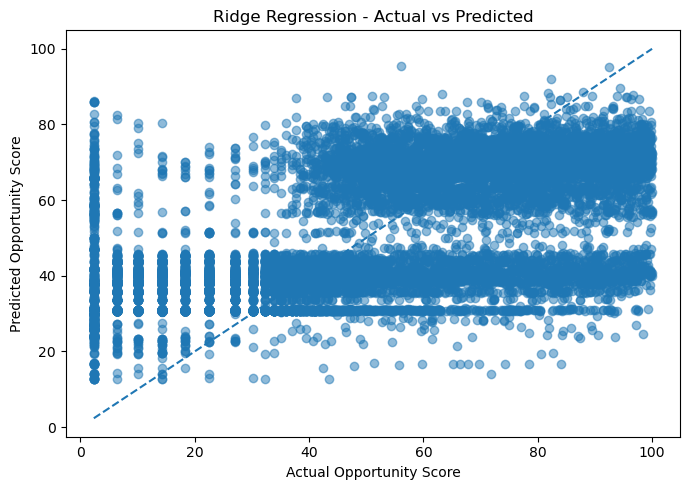

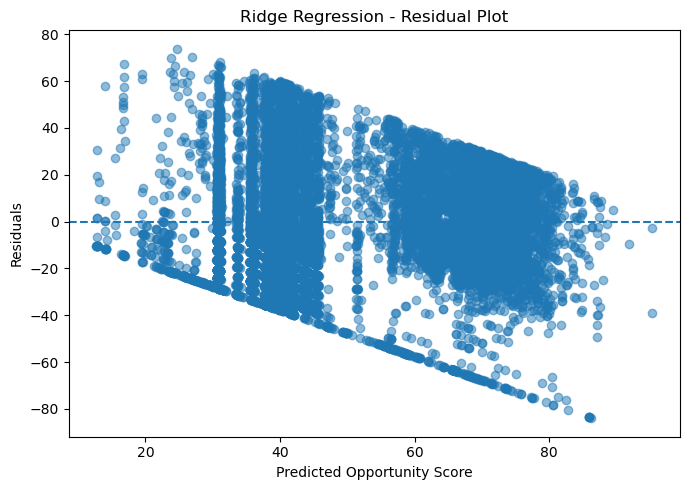

In [15]:

ridge_model = Ridge(alpha=1.0)


ridge_model.fit(X_reg_train_pca, y_reg_train)


y_pred_ridge = ridge_model.predict(X_reg_test_pca)


r2_ridge = r2_score(y_reg_test, y_pred_ridge)
rmse_ridge = np.sqrt(mean_squared_error(y_reg_test, y_pred_ridge))
mae_ridge = mean_absolute_error(y_reg_test, y_pred_ridge)

print("RIDGE REGRESSION")
print("-" * 40)
print(f"R²   : {r2_ridge:.4f}")
print(f"RMSE : {rmse_ridge:.4f}")
print(f"MAE  : {mae_ridge:.4f}")


plt.figure(figsize=(7, 5))
plt.scatter(y_reg_test, y_pred_ridge, alpha=0.5)
plt.plot(
    [y_reg_test.min(), y_reg_test.max()],
    [y_reg_test.min(), y_reg_test.max()],
    linestyle="--"
)
plt.xlabel("Actual Opportunity Score")
plt.ylabel("Predicted Opportunity Score")
plt.title("Ridge Regression - Actual vs Predicted")
plt.tight_layout()
plt.show()


residuals_ridge = y_reg_test - y_pred_ridge

plt.figure(figsize=(7, 5))
plt.scatter(y_pred_ridge, residuals_ridge, alpha=0.5)
plt.axhline(y=0, linestyle="--")
plt.xlabel("Predicted Opportunity Score")
plt.ylabel("Residuals")
plt.title("Ridge Regression - Residual Plot")
plt.tight_layout()
plt.show()

### 3. Lasso Regression

LASSO REGRESSION
----------------------------------------
R²   : 0.3500
RMSE : 23.1321
MAE  : 18.4907


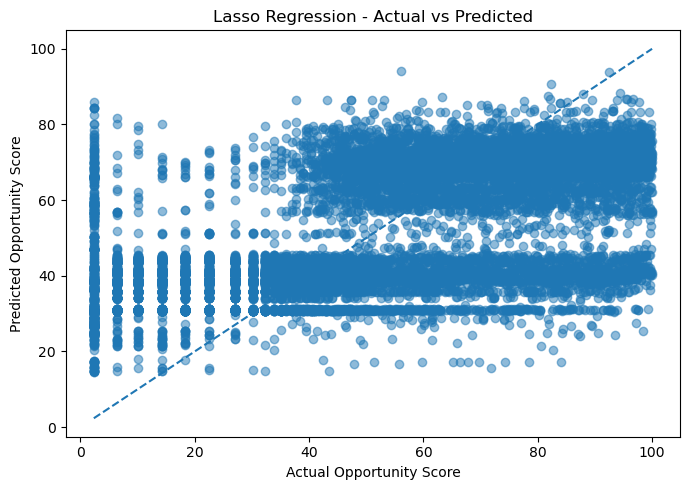

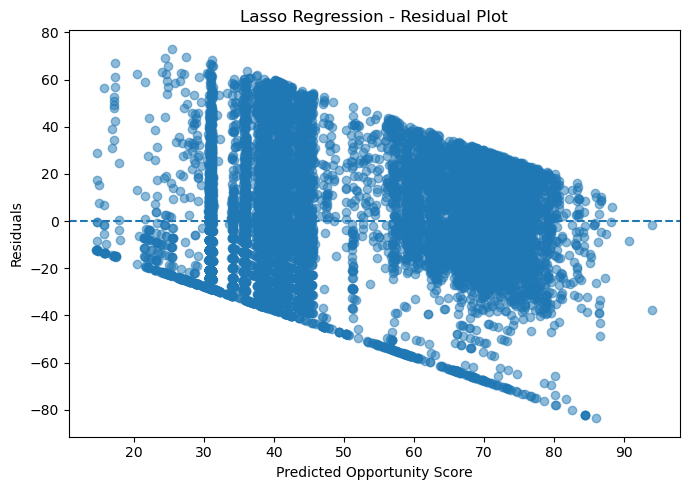

In [16]:
lasso_model = Lasso(
    alpha=0.01,
    max_iter=10000
)


lasso_model.fit(X_reg_train_pca, y_reg_train)


y_pred_lasso = lasso_model.predict(X_reg_test_pca)


r2_lasso = r2_score(y_reg_test, y_pred_lasso)
rmse_lasso = np.sqrt(mean_squared_error(y_reg_test, y_pred_lasso))
mae_lasso = mean_absolute_error(y_reg_test, y_pred_lasso)

print("LASSO REGRESSION")
print("-" * 40)
print(f"R²   : {r2_lasso:.4f}")
print(f"RMSE : {rmse_lasso:.4f}")
print(f"MAE  : {mae_lasso:.4f}")


plt.figure(figsize=(7, 5))
plt.scatter(y_reg_test, y_pred_lasso, alpha=0.5)
plt.plot(
    [y_reg_test.min(), y_reg_test.max()],
    [y_reg_test.min(), y_reg_test.max()],
    linestyle="--"
)
plt.xlabel("Actual Opportunity Score")
plt.ylabel("Predicted Opportunity Score")
plt.title("Lasso Regression - Actual vs Predicted")
plt.tight_layout()
plt.show()


residuals_lasso = y_reg_test - y_pred_lasso

plt.figure(figsize=(7, 5))
plt.scatter(y_pred_lasso, residuals_lasso, alpha=0.5)
plt.axhline(y=0, linestyle="--")
plt.xlabel("Predicted Opportunity Score")
plt.ylabel("Residuals")
plt.title("Lasso Regression - Residual Plot")
plt.tight_layout()
plt.show()

### 4. ElasticNet Regression

ELASTIC NET REGRESSION
----------------------------------------
R²   : 0.3470
RMSE : 23.1850
MAE  : 18.6291


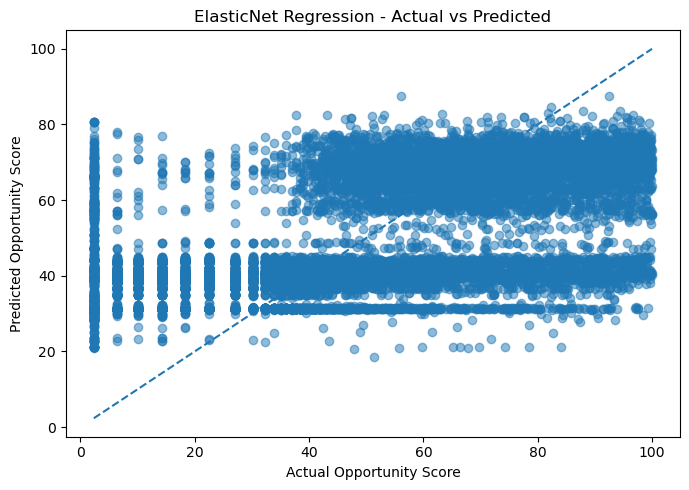

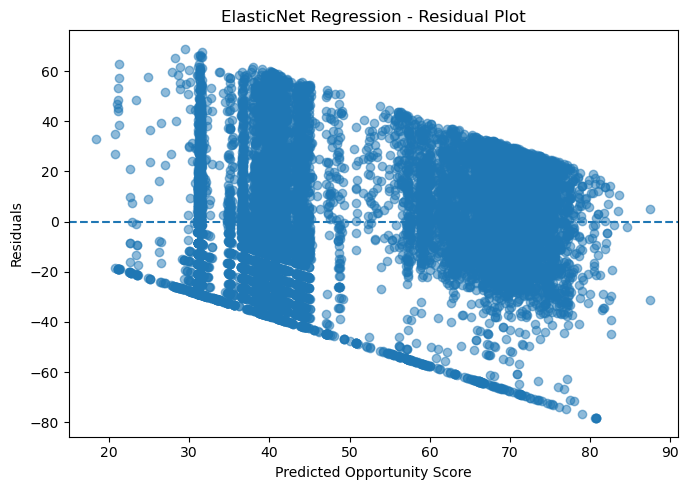

In [17]:

elastic_model = ElasticNet(
    alpha=0.01,
    l1_ratio=0.5,
    max_iter=10000,
    random_state=42
)


elastic_model.fit(X_reg_train_pca, y_reg_train)


y_pred_elastic = elastic_model.predict(X_reg_test_pca)


r2_elastic = r2_score(y_reg_test, y_pred_elastic)
rmse_elastic = np.sqrt(mean_squared_error(y_reg_test, y_pred_elastic))
mae_elastic = mean_absolute_error(y_reg_test, y_pred_elastic)

print("ELASTIC NET REGRESSION")
print("-" * 40)
print(f"R²   : {r2_elastic:.4f}")
print(f"RMSE : {rmse_elastic:.4f}")
print(f"MAE  : {mae_elastic:.4f}")


plt.figure(figsize=(7, 5))
plt.scatter(y_reg_test, y_pred_elastic, alpha=0.5)
plt.plot(
    [y_reg_test.min(), y_reg_test.max()],
    [y_reg_test.min(), y_reg_test.max()],
    linestyle="--"
)
plt.xlabel("Actual Opportunity Score")
plt.ylabel("Predicted Opportunity Score")
plt.title("ElasticNet Regression - Actual vs Predicted")
plt.tight_layout()
plt.show()


residuals_elastic = y_reg_test - y_pred_elastic

plt.figure(figsize=(7, 5))
plt.scatter(y_pred_elastic, residuals_elastic, alpha=0.5)
plt.axhline(y=0, linestyle="--")
plt.xlabel("Predicted Opportunity Score")
plt.ylabel("Residuals")
plt.title("ElasticNet Regression - Residual Plot")
plt.tight_layout()
plt.show()

### 5. Polynomial Regression

POLYNOMIAL REGRESSION
----------------------------------------
Degree : 2
R²     : 0.1017
RMSE   : 27.1942
MAE    : 17.4460


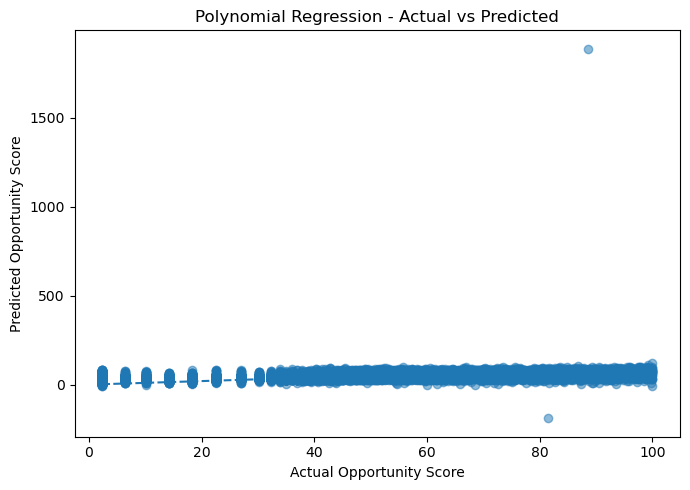

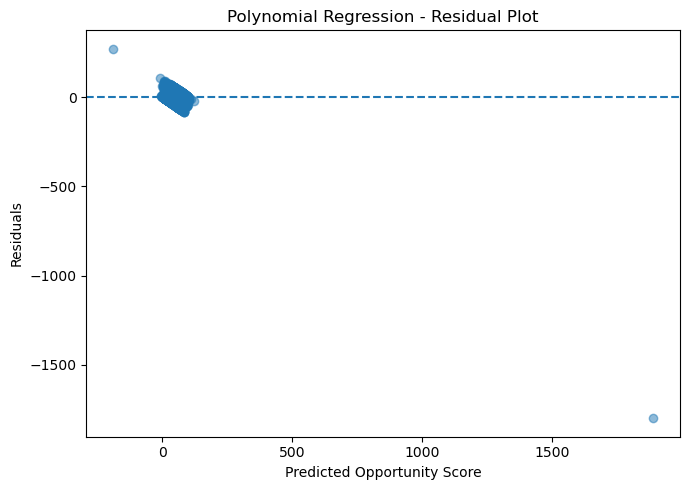

In [18]:
poly = PolynomialFeatures(
    degree=2,
    include_bias=False
)

X_reg_train_poly = poly.fit_transform(X_reg_train_pca)
X_reg_test_poly = poly.transform(X_reg_test_pca)


poly_model = LinearRegression()


poly_model.fit(X_reg_train_poly, y_reg_train)


y_pred_poly = poly_model.predict(X_reg_test_poly)


r2_poly = r2_score(y_reg_test, y_pred_poly)
rmse_poly = np.sqrt(mean_squared_error(y_reg_test, y_pred_poly))
mae_poly = mean_absolute_error(y_reg_test, y_pred_poly)

print("POLYNOMIAL REGRESSION")
print("-" * 40)
print("Degree : 2")
print(f"R²     : {r2_poly:.4f}")
print(f"RMSE   : {rmse_poly:.4f}")
print(f"MAE    : {mae_poly:.4f}")


plt.figure(figsize=(7, 5))
plt.scatter(y_reg_test, y_pred_poly, alpha=0.5)
plt.plot(
    [y_reg_test.min(), y_reg_test.max()],
    [y_reg_test.min(), y_reg_test.max()],
    linestyle="--"
)
plt.xlabel("Actual Opportunity Score")
plt.ylabel("Predicted Opportunity Score")
plt.title("Polynomial Regression - Actual vs Predicted")
plt.tight_layout()
plt.show()


residuals_poly = y_reg_test - y_pred_poly

plt.figure(figsize=(7, 5))
plt.scatter(y_pred_poly, residuals_poly, alpha=0.5)
plt.axhline(y=0, linestyle="--")
plt.xlabel("Predicted Opportunity Score")
plt.ylabel("Residuals")
plt.title("Polynomial Regression - Residual Plot")
plt.tight_layout()
plt.show()

### Comparison Table for first 5 Regression algorithms

In [19]:
comparison_df = pd.DataFrame({
    "Algorithm": [
        "Linear Regression",
        "Ridge Regression",
        "Lasso Regression",
        "ElasticNet Regression",
        "Polynomial Regression"
    ],
    "R²": [
        r2_linear,
        r2_ridge,
        r2_lasso,
        r2_elastic,
        r2_poly
    ],
    "RMSE": [
        rmse_linear,
        rmse_ridge,
        rmse_lasso,
        rmse_elastic,
        rmse_poly
    ],
    "MAE": [
        mae_linear,
        mae_ridge,
        mae_lasso,
        mae_elastic,
        mae_poly
    ]
})


comparison_df = comparison_df.sort_values(
    by="R²",
    ascending=False
).reset_index(drop=True)


comparison_df["R²"] = comparison_df["R²"].round(4)
comparison_df["RMSE"] = comparison_df["RMSE"].round(4)
comparison_df["MAE"] = comparison_df["MAE"].round(4)

print("Regression Model Comparison - Opportunity Score")
display(comparison_df)


Regression Model Comparison - Opportunity Score


,Algorithm,R²,RMSE,MAE
0,Ridge Regression,0.3501,23.1305,18.4716
1,Linear Regression,0.3501,23.1305,18.4711
2,Lasso Regression,0.3500,23.1321,18.4907
3,ElasticNet Regression,0.3470,23.1850,18.6291
4,Polynomial Regression,0.1017,27.1942,17.4460


### 6. Decision Tree Regressor

DECISION TREE REGRESSOR
----------------------------------------
R²   : 0.4091
RMSE : 22.0554
MAE  : 17.0248


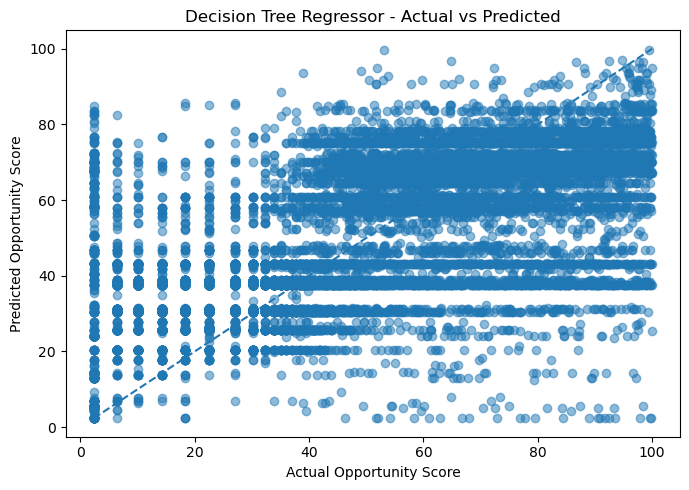

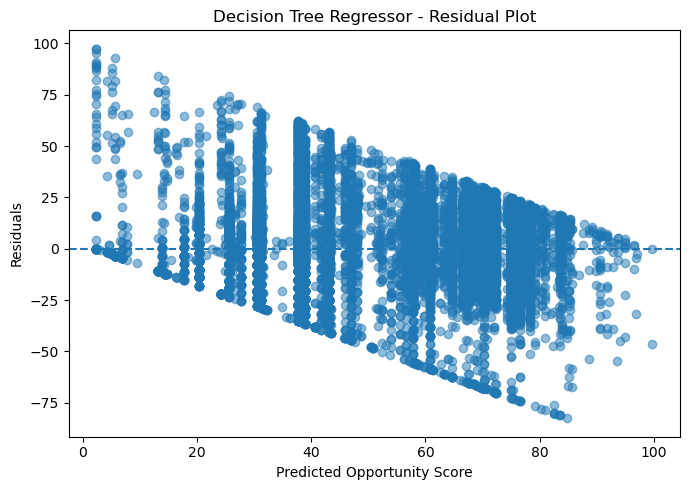

In [20]:
# ============================================
# 6. DECISION TREE REGRESSOR
# ============================================

dt_reg_model = DecisionTreeRegressor(
    max_depth=10,
    random_state=RANDOM_STATE
)

# Fit
dt_reg_model.fit(X_reg_train_pca, y_reg_train)

# Predict
y_pred_dt_reg = dt_reg_model.predict(X_reg_test_pca)

# Metrics
r2_dt_reg = r2_score(y_reg_test, y_pred_dt_reg)
rmse_dt_reg = np.sqrt(mean_squared_error(y_reg_test, y_pred_dt_reg))
mae_dt_reg = mean_absolute_error(y_reg_test, y_pred_dt_reg)

print("DECISION TREE REGRESSOR")
print("-" * 40)
print(f"R²   : {r2_dt_reg:.4f}")
print(f"RMSE : {rmse_dt_reg:.4f}")
print(f"MAE  : {mae_dt_reg:.4f}")

# Actual vs Predicted
plt.figure(figsize=(7, 5))
plt.scatter(y_reg_test, y_pred_dt_reg, alpha=0.5)
plt.plot(
    [y_reg_test.min(), y_reg_test.max()],
    [y_reg_test.min(), y_reg_test.max()],
    linestyle="--"
)
plt.xlabel("Actual Opportunity Score")
plt.ylabel("Predicted Opportunity Score")
plt.title("Decision Tree Regressor - Actual vs Predicted")
plt.tight_layout()
plt.show()

# Residual Plot
residuals_dt_reg = y_reg_test - y_pred_dt_reg

plt.figure(figsize=(7, 5))
plt.scatter(y_pred_dt_reg, residuals_dt_reg, alpha=0.5)
plt.axhline(y=0, linestyle="--")
plt.xlabel("Predicted Opportunity Score")
plt.ylabel("Residuals")
plt.title("Decision Tree Regressor - Residual Plot")
plt.tight_layout()
plt.show()

### Decision Tree Structure Visualization

This visualization shows how the **Decision Tree Regressor** branches through the PCA components to make an Opportunity Score prediction.

For readability, only the **first 3 levels** of the trained tree are displayed. The actual model is still trained with `max_depth=10`.


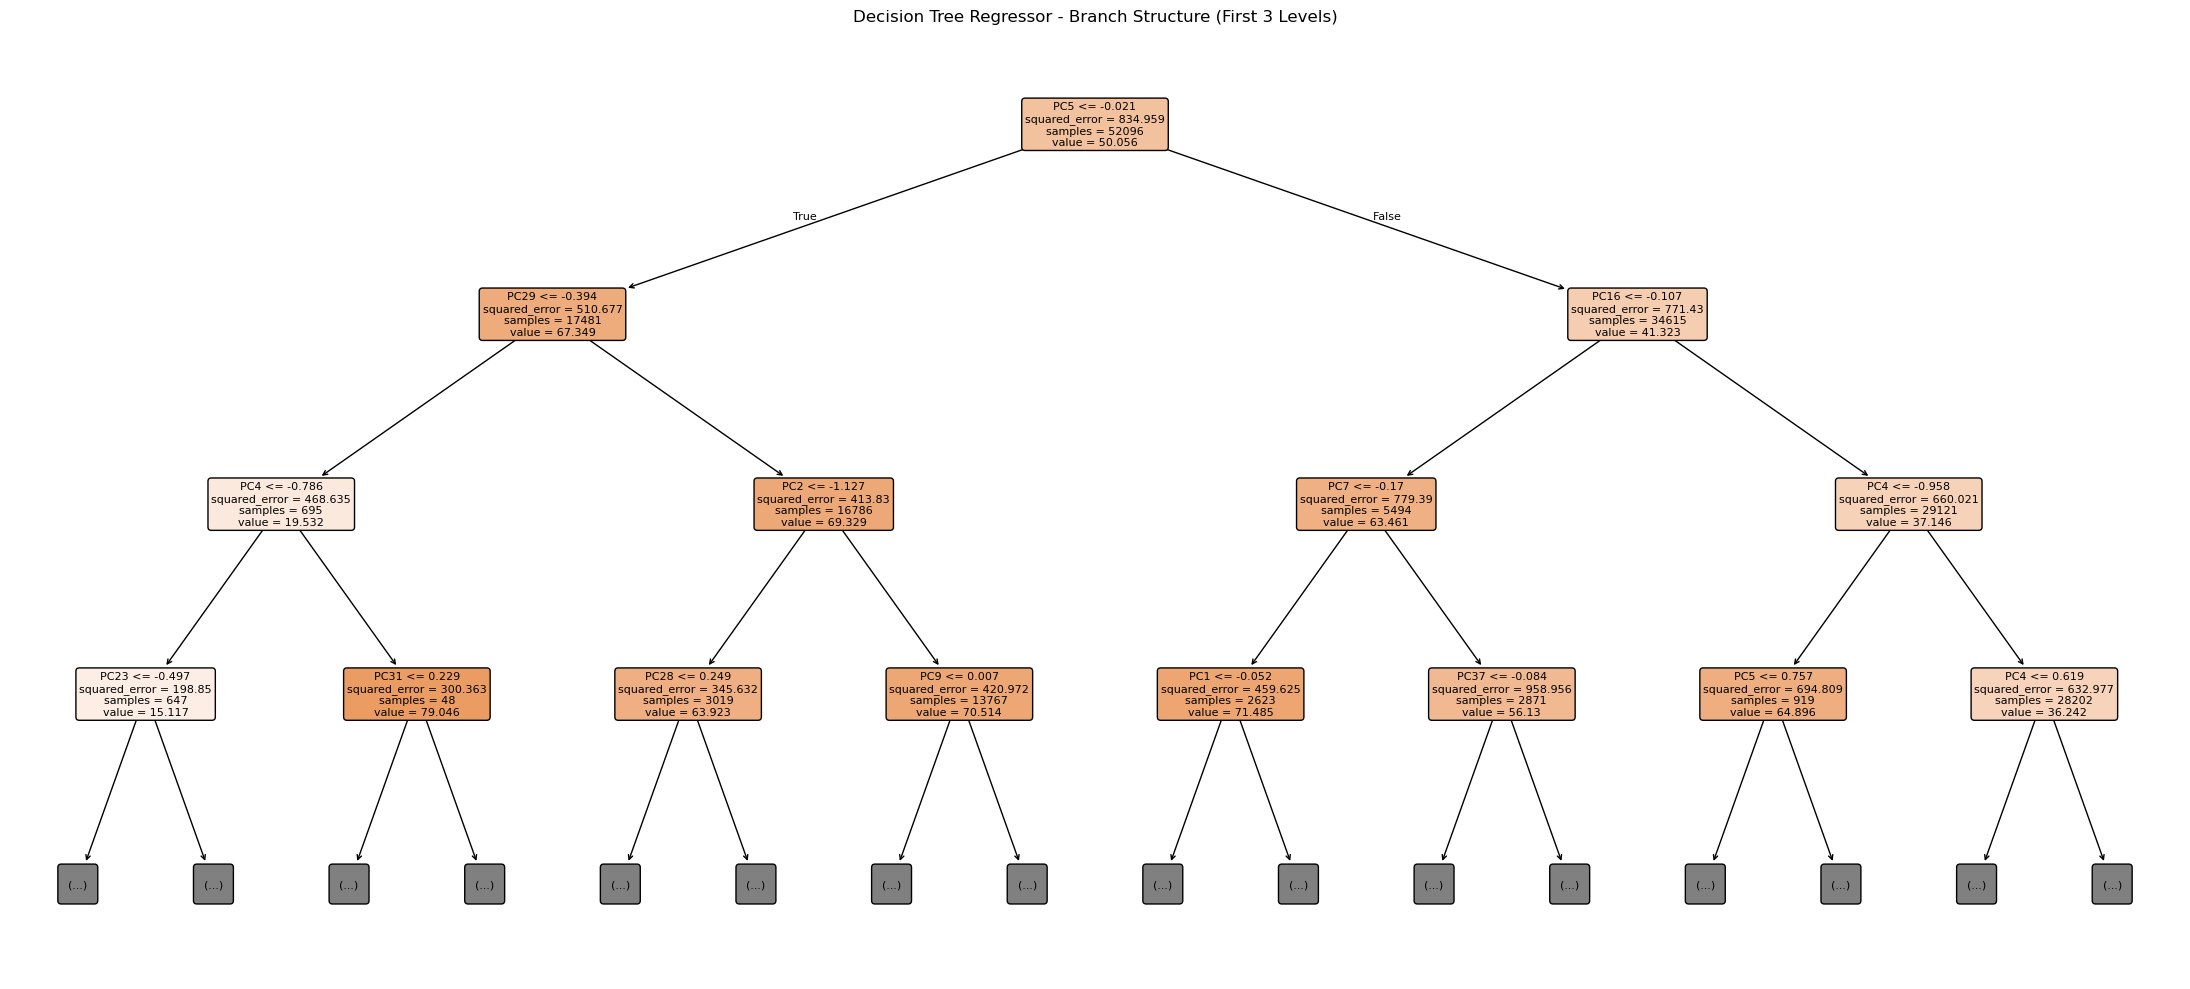

In [21]:
# ============================================
# DECISION TREE - BRANCH VISUALIZATION
# ============================================

plt.figure(figsize=(22, 10))

plot_tree(
    dt_reg_model,
    max_depth=3,
    feature_names=[f"PC{i+1}" for i in range(X_reg_train_pca.shape[1])],
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Decision Tree Regressor - Branch Structure (First 3 Levels)")
plt.tight_layout()
plt.show()


### 7. Random Forest Regressor

RANDOM FOREST REGRESSOR
----------------------------------------
R²   : 0.4595
RMSE : 21.0929
MAE  : 16.5531


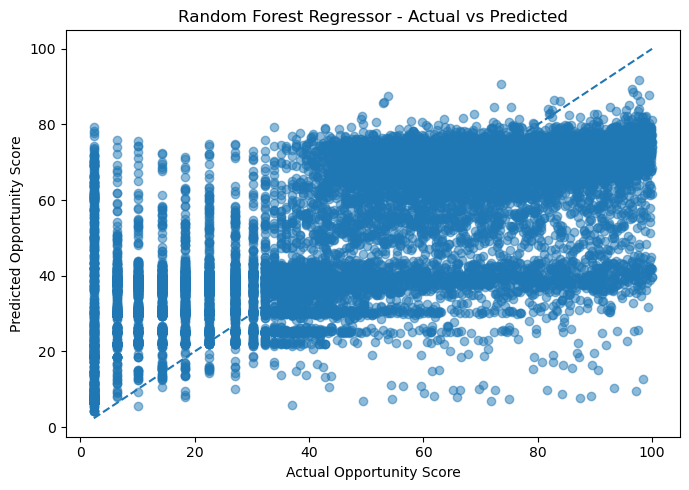

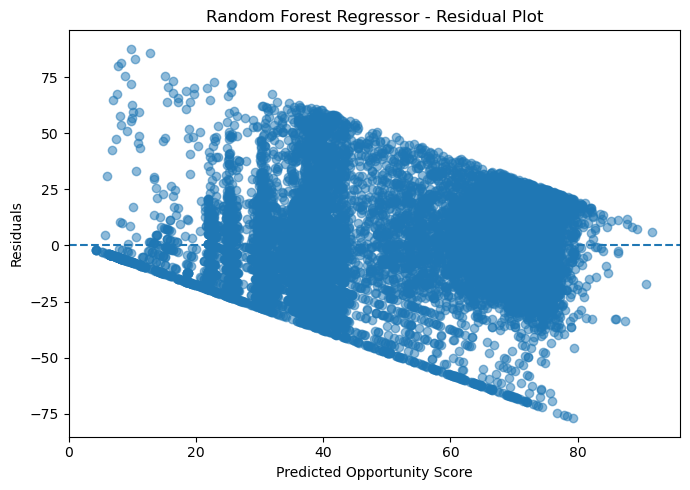

In [22]:
# ============================================
# 7. RANDOM FOREST REGRESSOR
# ============================================

rf_reg_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

# Fit
rf_reg_model.fit(X_reg_train_pca, y_reg_train)

# Predict
y_pred_rf_reg = rf_reg_model.predict(X_reg_test_pca)

# Metrics
r2_rf_reg = r2_score(y_reg_test, y_pred_rf_reg)
rmse_rf_reg = np.sqrt(mean_squared_error(y_reg_test, y_pred_rf_reg))
mae_rf_reg = mean_absolute_error(y_reg_test, y_pred_rf_reg)

print("RANDOM FOREST REGRESSOR")
print("-" * 40)
print(f"R²   : {r2_rf_reg:.4f}")
print(f"RMSE : {rmse_rf_reg:.4f}")
print(f"MAE  : {mae_rf_reg:.4f}")

# Actual vs Predicted
plt.figure(figsize=(7, 5))
plt.scatter(y_reg_test, y_pred_rf_reg, alpha=0.5)
plt.plot(
    [y_reg_test.min(), y_reg_test.max()],
    [y_reg_test.min(), y_reg_test.max()],
    linestyle="--"
)
plt.xlabel("Actual Opportunity Score")
plt.ylabel("Predicted Opportunity Score")
plt.title("Random Forest Regressor - Actual vs Predicted")
plt.tight_layout()
plt.show()

# Residual Plot
residuals_rf_reg = y_reg_test - y_pred_rf_reg

plt.figure(figsize=(7, 5))
plt.scatter(y_pred_rf_reg, residuals_rf_reg, alpha=0.5)
plt.axhline(y=0, linestyle="--")
plt.xlabel("Predicted Opportunity Score")
plt.ylabel("Residuals")
plt.title("Random Forest Regressor - Residual Plot")
plt.tight_layout()
plt.show()

### 8. Gradient Boosting Regressor

GRADIENT BOOSTING REGRESSOR
----------------------------------------
R²   : 0.4270
RMSE : 21.7194
MAE  : 17.2083


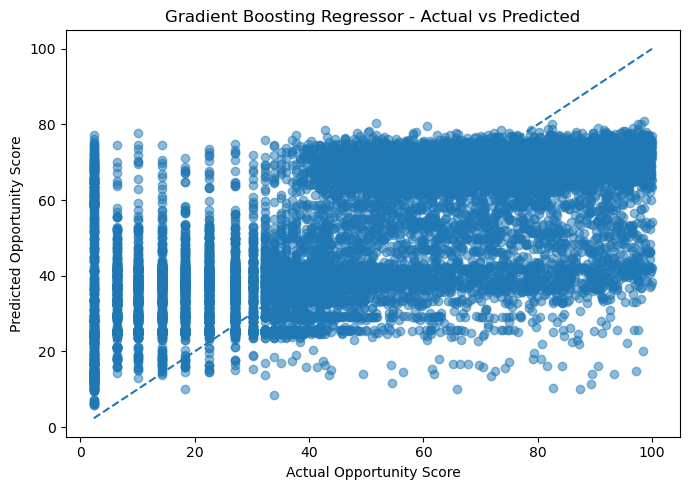

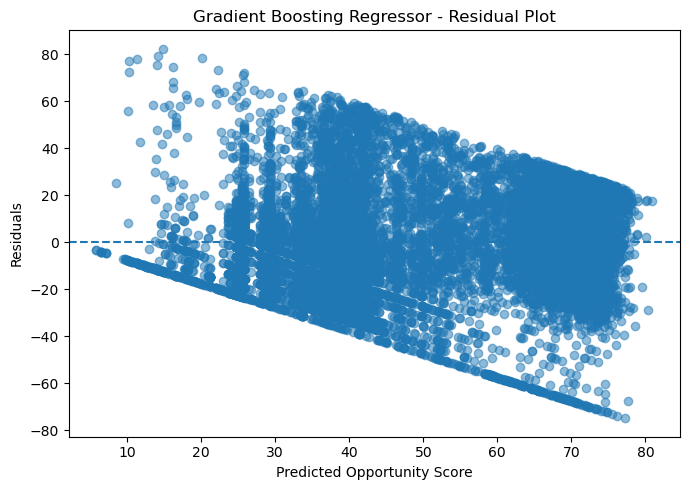

In [23]:
# ============================================
# 8. GRADIENT BOOSTING REGRESSOR
# ============================================

gb_reg_model = GradientBoostingRegressor(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.1,
    random_state=RANDOM_STATE
)

# Fit
gb_reg_model.fit(X_reg_train_pca, y_reg_train)

# Predict
y_pred_gb_reg = gb_reg_model.predict(X_reg_test_pca)

# Metrics
r2_gb_reg = r2_score(y_reg_test, y_pred_gb_reg)
rmse_gb_reg = np.sqrt(mean_squared_error(y_reg_test, y_pred_gb_reg))
mae_gb_reg = mean_absolute_error(y_reg_test, y_pred_gb_reg)

print("GRADIENT BOOSTING REGRESSOR")
print("-" * 40)
print(f"R²   : {r2_gb_reg:.4f}")
print(f"RMSE : {rmse_gb_reg:.4f}")
print(f"MAE  : {mae_gb_reg:.4f}")

# Actual vs Predicted
plt.figure(figsize=(7, 5))
plt.scatter(y_reg_test, y_pred_gb_reg, alpha=0.5)
plt.plot(
    [y_reg_test.min(), y_reg_test.max()],
    [y_reg_test.min(), y_reg_test.max()],
    linestyle="--"
)
plt.xlabel("Actual Opportunity Score")
plt.ylabel("Predicted Opportunity Score")
plt.title("Gradient Boosting Regressor - Actual vs Predicted")
plt.tight_layout()
plt.show()

# Residual Plot
residuals_gb_reg = y_reg_test - y_pred_gb_reg

plt.figure(figsize=(7, 5))
plt.scatter(y_pred_gb_reg, residuals_gb_reg, alpha=0.5)
plt.axhline(y=0, linestyle="--")
plt.xlabel("Predicted Opportunity Score")
plt.ylabel("Residuals")
plt.title("Gradient Boosting Regressor - Residual Plot")
plt.tight_layout()
plt.show()

### 9. Support Vector Regressor (SVR)

SUPPORT VECTOR REGRESSOR
----------------------------------------
Training samples used : 10000
Test samples used     : 3000
R²   : 0.0847
RMSE : 27.6810
MAE  : 21.9406


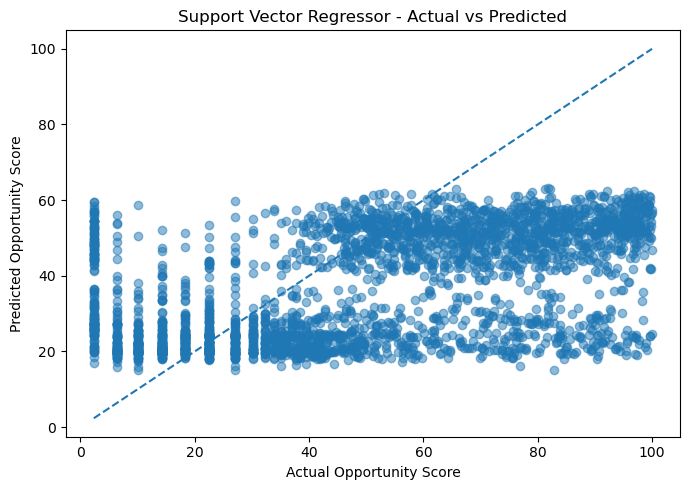

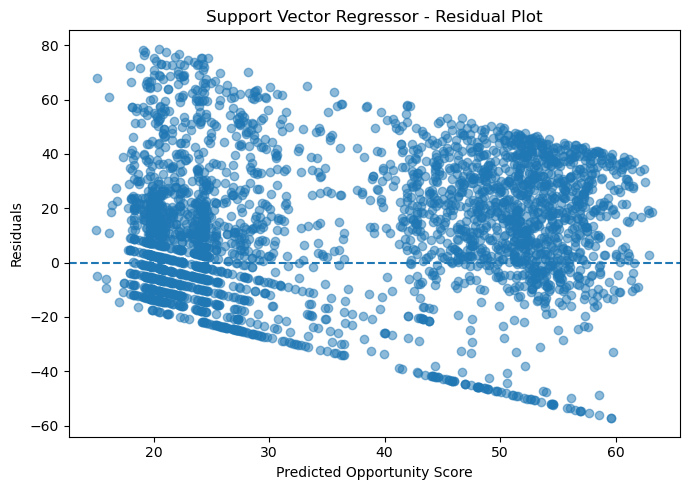

In [24]:
# ============================================
# 9. SUPPORT VECTOR REGRESSOR (SVR) - FAST
# ============================================

from sklearn.svm import SVR
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import numpy as np
import matplotlib.pyplot as plt

# --------------------------------------------
# CAP DATASET FOR FASTER SVR TRAINING
# --------------------------------------------

MAX_TRAIN_SAMPLES = 10000
MAX_TEST_SAMPLES = 3000

# Random sampling for training data
np.random.seed(42)

if len(X_reg_train_pca) > MAX_TRAIN_SAMPLES:
    train_indices = np.random.choice(
        len(X_reg_train_pca),
        MAX_TRAIN_SAMPLES,
        replace=False
    )
    X_svr_train = X_reg_train_pca[train_indices]
    y_svr_train = y_reg_train.iloc[train_indices] if hasattr(y_reg_train, "iloc") else y_reg_train[train_indices]
else:
    X_svr_train = X_reg_train_pca
    y_svr_train = y_reg_train

# Random sampling for test data
if len(X_reg_test_pca) > MAX_TEST_SAMPLES:
    test_indices = np.random.choice(
        len(X_reg_test_pca),
        MAX_TEST_SAMPLES,
        replace=False
    )
    X_svr_test = X_reg_test_pca[test_indices]
    y_svr_test = y_reg_test.iloc[test_indices] if hasattr(y_reg_test, "iloc") else y_reg_test[test_indices]
else:
    X_svr_test = X_reg_test_pca
    y_svr_test = y_reg_test


# --------------------------------------------
# SVR MODEL
# --------------------------------------------

svr_model = SVR(
    kernel="rbf",
    C=1.0,
    epsilon=0.1,
    gamma="scale",
    cache_size=2000,
    max_iter=3000
)

# Fit
svr_model.fit(X_svr_train, y_svr_train)

# Predict
y_pred_svr = svr_model.predict(X_svr_test)


# --------------------------------------------
# METRICS
# --------------------------------------------

r2_svr = r2_score(y_svr_test, y_pred_svr)

rmse_svr = np.sqrt(
    mean_squared_error(y_svr_test, y_pred_svr)
)

mae_svr = mean_absolute_error(
    y_svr_test,
    y_pred_svr
)


print("SUPPORT VECTOR REGRESSOR")
print("-" * 40)
print(f"Training samples used : {len(X_svr_train)}")
print(f"Test samples used     : {len(X_svr_test)}")
print(f"R²   : {r2_svr:.4f}")
print(f"RMSE : {rmse_svr:.4f}")
print(f"MAE  : {mae_svr:.4f}")


# --------------------------------------------
# ACTUAL VS PREDICTED
# --------------------------------------------

plt.figure(figsize=(7, 5))

plt.scatter(
    y_svr_test,
    y_pred_svr,
    alpha=0.5
)

plt.plot(
    [y_svr_test.min(), y_svr_test.max()],
    [y_svr_test.min(), y_svr_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Opportunity Score")
plt.ylabel("Predicted Opportunity Score")
plt.title("Support Vector Regressor - Actual vs Predicted")
plt.tight_layout()
plt.show()


# --------------------------------------------
# RESIDUAL PLOT
# --------------------------------------------

residuals_svr = y_svr_test - y_pred_svr

plt.figure(figsize=(7, 5))

plt.scatter(
    y_pred_svr,
    residuals_svr,
    alpha=0.5
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted Opportunity Score")
plt.ylabel("Residuals")
plt.title("Support Vector Regressor - Residual Plot")
plt.tight_layout()
plt.show()

### 10. K-Nearest Neighbors Regressor

K-NEAREST NEIGHBORS REGRESSOR
----------------------------------------
R²   : 0.5020
RMSE : 20.2480
MAE  : 13.5410


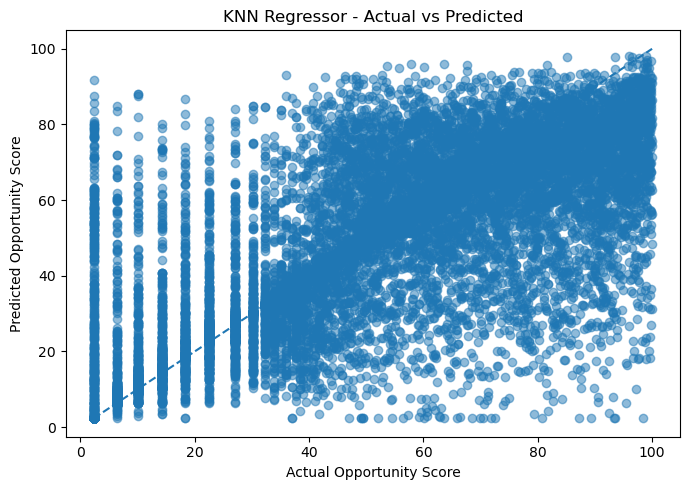

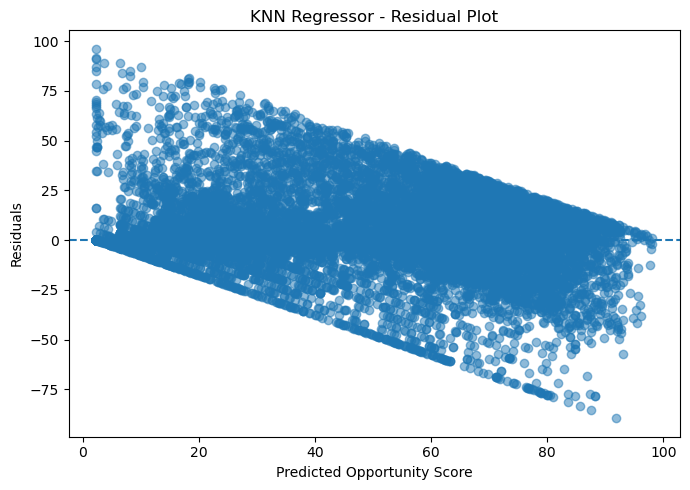

In [25]:
# ============================================
# 10. K-NEAREST NEIGHBORS REGRESSOR
# ============================================

knn_reg_model = KNeighborsRegressor(
    n_neighbors=7,
    weights="distance"
)

# Fit
knn_reg_model.fit(X_reg_train_pca, y_reg_train)

# Predict
y_pred_knn_reg = knn_reg_model.predict(X_reg_test_pca)

# Metrics
r2_knn_reg = r2_score(y_reg_test, y_pred_knn_reg)
rmse_knn_reg = np.sqrt(mean_squared_error(y_reg_test, y_pred_knn_reg))
mae_knn_reg = mean_absolute_error(y_reg_test, y_pred_knn_reg)

print("K-NEAREST NEIGHBORS REGRESSOR")
print("-" * 40)
print(f"R²   : {r2_knn_reg:.4f}")
print(f"RMSE : {rmse_knn_reg:.4f}")
print(f"MAE  : {mae_knn_reg:.4f}")

# Actual vs Predicted
plt.figure(figsize=(7, 5))
plt.scatter(y_reg_test, y_pred_knn_reg, alpha=0.5)
plt.plot(
    [y_reg_test.min(), y_reg_test.max()],
    [y_reg_test.min(), y_reg_test.max()],
    linestyle="--"
)
plt.xlabel("Actual Opportunity Score")
plt.ylabel("Predicted Opportunity Score")
plt.title("KNN Regressor - Actual vs Predicted")
plt.tight_layout()
plt.show()

# Residual Plot
residuals_knn_reg = y_reg_test - y_pred_knn_reg

plt.figure(figsize=(7, 5))
plt.scatter(y_pred_knn_reg, residuals_knn_reg, alpha=0.5)
plt.axhline(y=0, linestyle="--")
plt.xlabel("Predicted Opportunity Score")
plt.ylabel("Residuals")
plt.title("KNN Regressor - Residual Plot")
plt.tight_layout()
plt.show()

### Comparison Table for Regression Algorithms 6–10

This table follows the same format as the comparison table for Regression Algorithms 1–5.


In [26]:
# ============================================
# REGRESSION MODEL COMPARISON - ALGORITHMS 6-10
# ============================================

comparison_df_6_10 = pd.DataFrame({
    "Algorithm": [
        "Decision Tree Regressor",
        "Random Forest Regressor",
        "Gradient Boosting Regressor",
        "Support Vector Regressor",
        "K-Nearest Neighbors Regressor"
    ],
    "R²": [
        r2_dt_reg,
        r2_rf_reg,
        r2_gb_reg,
        r2_svr,
        r2_knn_reg
    ],
    "RMSE": [
        rmse_dt_reg,
        rmse_rf_reg,
        rmse_gb_reg,
        rmse_svr,
        rmse_knn_reg
    ],
    "MAE": [
        mae_dt_reg,
        mae_rf_reg,
        mae_gb_reg,
        mae_svr,
        mae_knn_reg
    ]
})

# Rank models by R²
comparison_df_6_10 = comparison_df_6_10.sort_values(
    by="R²",
    ascending=False
).reset_index(drop=True)

# Round values for display
comparison_df_6_10["R²"] = comparison_df_6_10["R²"].round(4)
comparison_df_6_10["RMSE"] = comparison_df_6_10["RMSE"].round(4)
comparison_df_6_10["MAE"] = comparison_df_6_10["MAE"].round(4)

print("Regression Model Comparison - Algorithms 6-10")
display(comparison_df_6_10)


Regression Model Comparison - Algorithms 6-10


,Algorithm,R²,RMSE,MAE
0,K-Nearest Neighbors Regressor,0.5020,20.2480,13.5410
1,Random Forest Regressor,0.4595,21.0929,16.5531
2,Gradient Boosting Regressor,0.4270,21.7194,17.2083
3,Decision Tree Regressor,0.4091,22.0554,17.0248
4,Support Vector Regressor,0.0847,27.6810,21.9406


## 4. CLASSIFICATION — 5 Algorithms

### Classification Target — `Profit_Potential`

`Profit_Potential` is the categorical target for the classification task.

| Class | Meaning |
|---|---|
| **Low** | Lower calculated opportunity; the location is relatively close to existing stations. |
| **Medium** | Moderate calculated opportunity. |
| **High** | Higher calculated opportunity; the location is relatively farther from existing stations. |

Use:
- `X_clf_train_pca`
- `X_clf_test_pca`
- `y_clf_train`
- `y_clf_test`

### Mandatory metrics
- Accuracy
- Precision
- Recall
- F1-score
- Confusion Matrix
- ROC-AUC


### 1. Logistic Regression

In [27]:
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=RANDOM_STATE
)

logistic_model.fit(
    X_clf_train_pca,
    y_clf_train
)

y_pred_logistic = logistic_model.predict(
    X_clf_test_pca
)

y_prob_logistic = logistic_model.predict_proba(
    X_clf_test_pca
)

print("Accuracy:",
      round(accuracy_score(y_clf_test, y_pred_logistic), 4))

print("Precision:",
      round(
          precision_score(
              y_clf_test,
              y_pred_logistic,
              average="weighted",
              zero_division=0
          ), 4
      ))

print("Recall:",
      round(
          recall_score(
              y_clf_test,
              y_pred_logistic,
              average="weighted",
              zero_division=0
          ), 4
      ))

print("F1 Score:",
      round(
          f1_score(
              y_clf_test,
              y_pred_logistic,
              average="weighted",
              zero_division=0
          ), 4
      ))

print("ROC-AUC:",
      round(
          roc_auc_score(
              y_clf_test,
              y_prob_logistic,
              multi_class="ovr"
          ), 4
      ))

print("\nClassification Report:")
print(
    classification_report(
        y_clf_test,
        y_pred_logistic,
        zero_division=0
    )
)

print("Confusion Matrix:")
display(
    pd.DataFrame(
        confusion_matrix(
            y_clf_test,
            y_pred_logistic
        ),
        index=logistic_model.classes_,
        columns=logistic_model.classes_
    )
)

Accuracy: 0.5611
Precision: 0.5456
Recall: 0.5611
F1 Score: 0.5041
ROC-AUC: 0.7373

Classification Report:
              precision    recall  f1-score   support

        High       0.60      0.64      0.62      4343
         Low       0.55      0.91      0.68      4340
      Medium       0.49      0.13      0.21      4342

    accuracy                           0.56     13025
   macro avg       0.55      0.56      0.50     13025
weighted avg       0.55      0.56      0.50     13025

Confusion Matrix:


,High,Low,Medium
High,2789,1103,451
Low,243,3945,152
Medium,1597,2171,574


### 2. K-Nearest Neighbors

In [28]:
knn_model = KNeighborsClassifier(
    n_neighbors=7,
    weights="distance"
)

knn_model.fit(
    X_clf_train_pca,
    y_clf_train
)

y_pred_knn = knn_model.predict(
    X_clf_test_pca
)

y_prob_knn = knn_model.predict_proba(
    X_clf_test_pca
)

print("Accuracy:",
      round(accuracy_score(y_clf_test, y_pred_knn), 4))

print("Precision:",
      round(
          precision_score(
              y_clf_test,
              y_pred_knn,
              average="weighted",
              zero_division=0
          ), 4
      ))

print("Recall:",
      round(
          recall_score(
              y_clf_test,
              y_pred_knn,
              average="weighted",
              zero_division=0
          ), 4
      ))

print("F1 Score:",
      round(
          f1_score(
              y_clf_test,
              y_pred_knn,
              average="weighted",
              zero_division=0
          ), 4
      ))

print("ROC-AUC:",
      round(
          roc_auc_score(
              y_clf_test,
              y_prob_knn,
              multi_class="ovr"
          ), 4
      ))

print("\nClassification Report:")
print(
    classification_report(
        y_clf_test,
        y_pred_knn,
        zero_division=0
    )
)

print("Confusion Matrix:")
display(
    pd.DataFrame(
        confusion_matrix(
            y_clf_test,
            y_pred_knn
        ),
        index=knn_model.classes_,
        columns=knn_model.classes_
    )
)

Accuracy: 0.6701
Precision: 0.6643
Recall: 0.6701
F1 Score: 0.6651
ROC-AUC: 0.8332

Classification Report:
              precision    recall  f1-score   support

        High       0.67      0.62      0.64      4343
         Low       0.73      0.85      0.79      4340
      Medium       0.59      0.54      0.56      4342

    accuracy                           0.67     13025
   macro avg       0.66      0.67      0.67     13025
weighted avg       0.66      0.67      0.67     13025

Confusion Matrix:


,High,Low,Medium
High,2699,480,1164
Low,206,3691,443
Medium,1145,859,2338


### 3. Gaussian Naive Bayes

In [29]:
nb_model = GaussianNB()

nb_model.fit(
    X_clf_train_pca,
    y_clf_train
)

y_pred_nb = nb_model.predict(
    X_clf_test_pca
)

y_prob_nb = nb_model.predict_proba(
    X_clf_test_pca
)

print("Accuracy:",
      round(accuracy_score(y_clf_test, y_pred_nb), 4))

print("Precision:",
      round(
          precision_score(
              y_clf_test,
              y_pred_nb,
              average="weighted",
              zero_division=0
          ), 4
      ))

print("Recall:",
      round(
          recall_score(
              y_clf_test,
              y_pred_nb,
              average="weighted",
              zero_division=0
          ), 4
      ))

print("F1 Score:",
      round(
          f1_score(
              y_clf_test,
              y_pred_nb,
              average="weighted",
              zero_division=0
          ), 4
      ))

print("ROC-AUC:",
      round(
          roc_auc_score(
              y_clf_test,
              y_prob_nb,
              multi_class="ovr"
          ), 4
      ))

print("\nClassification Report:")
print(
    classification_report(
        y_clf_test,
        y_pred_nb,
        zero_division=0
    )
)

print("Confusion Matrix:")
display(
    pd.DataFrame(
        confusion_matrix(
            y_clf_test,
            y_pred_nb
        ),
        index=nb_model.classes_,
        columns=nb_model.classes_
    )
)

Accuracy: 0.4885
Precision: 0.472
Recall: 0.4885
F1 Score: 0.4667
ROC-AUC: 0.6735

Classification Report:
              precision    recall  f1-score   support

        High       0.49      0.48      0.49      4343
         Low       0.52      0.74      0.61      4340
      Medium       0.40      0.24      0.30      4342

    accuracy                           0.49     13025
   macro avg       0.47      0.49      0.47     13025
weighted avg       0.47      0.49      0.47     13025

Confusion Matrix:


,High,Low,Medium
High,2101,1008,1234
Low,812,3231,297
Medium,1358,1953,1031


### 4. Decision Tree Classifier

In [ ]:
dt_model = DecisionTreeClassifier(
    max_depth=10,
    random_state=RANDOM_STATE
)

dt_model.fit(
    X_clf_train_pca,
    y_clf_train
)

y_pred_dt = dt_model.predict(
    X_clf_test_pca
)

y_prob_dt = dt_model.predict_proba(
    X_clf_test_pca
)

print("Accuracy:",
      round(accuracy_score(y_clf_test, y_pred_dt), 4))

print("Precision:",
      round(
          precision_score(
              y_clf_test,
              y_pred_dt,
              average="weighted",
              zero_division=0
          ), 4
      ))

print("Recall:",
      round(
          recall_score(
              y_clf_test,
              y_pred_dt,
              average="weighted",
              zero_division=0
          ), 4
      ))

print("F1 Score:",
      round(
          f1_score(
              y_clf_test,
              y_pred_dt,
              average="weighted",
              zero_division=0
          ), 4
      ))

print("ROC-AUC:",
      round(
          roc_auc_score(
              y_clf_test,
              y_prob_dt,
              multi_class="ovr"
          ), 4
      ))

print("\nClassification Report:")
print(
    classification_report(
        y_clf_test,
        y_pred_dt,
        zero_division=0
    )
)

print("Confusion Matrix:")
display(
    pd.DataFrame(
        confusion_matrix(
            y_clf_test,
            y_pred_dt
        ),
        index=dt_model.classes_,
        columns=dt_model.classes_
    )
)
print(X_clf_train_pca.shape)

### 5. Support Vector Machine (SVC)

Because the dataset contains about 65,000 observations, a full RBF SVC can take a very long time to train.

For this final notebook, SVC is trained on a **stratified capped sample of 10,000 training observations**. This keeps all three classes represented while making SVC practical to run.

We also use:
- `kernel="linear"` for faster training
- `probability=False` because probability calibration makes SVC considerably slower

The test set is kept unchanged, so SVC is evaluated on the same test data as the other classification models.


In [ ]:
# ============================================
# 5. SUPPORT VECTOR MACHINE (SVC)
# Multiclass - Fast Version
# ============================================

from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import label_binarize
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

import pandas as pd
import numpy as np


# ============================================
# 1. CAP SVC TRAINING DATA
# ============================================

SVC_MAX_TRAIN_ROWS = 10000

if len(y_clf_train) > SVC_MAX_TRAIN_ROWS:

    X_svc_train, _, y_svc_train, _ = train_test_split(
        X_clf_train_pca,
        y_clf_train,
        train_size=SVC_MAX_TRAIN_ROWS,
        random_state=RANDOM_STATE,
        stratify=y_clf_train
    )

else:

    X_svc_train = X_clf_train_pca
    y_svc_train = y_clf_train


print("Original SVC training rows:", len(y_clf_train))
print("Capped SVC training rows   :", len(y_svc_train))


# ============================================
# 2. CREATE SVC MODEL
# ============================================

svc_model = SVC(
    kernel="linear",
    C=1.0,
    probability=False,
    random_state=RANDOM_STATE,
    decision_function_shape="ovr"
)


# ============================================
# 3. TRAIN MODEL
# ============================================

svc_model.fit(
    X_svc_train,
    y_svc_train
)


# ============================================
# 4. PREDICTION
# ============================================

# Predicted class labels
y_pred_svc = svc_model.predict(
    X_clf_test_pca
)

# Decision scores for ROC-AUC
y_score_svc = svc_model.decision_function(
    X_clf_test_pca
)


# ============================================
# 5. ACCURACY
# ============================================

accuracy_svc = accuracy_score(
    y_clf_test,
    y_pred_svc
)

print("\nSUPPORT VECTOR MACHINE (SVC)")
print("=" * 50)

print(f"Accuracy  : {accuracy_svc:.4f}")


# ============================================
# 6. PRECISION
# ============================================

precision_svc = precision_score(
    y_clf_test,
    y_pred_svc,
    average="weighted",
    zero_division=0
)

print(f"Precision : {precision_svc:.4f}")


# ============================================
# 7. RECALL
# ============================================

recall_svc = recall_score(
    y_clf_test,
    y_pred_svc,
    average="weighted",
    zero_division=0
)

print(f"Recall    : {recall_svc:.4f}")


# ============================================
# 8. F1 SCORE
# ============================================

f1_svc = f1_score(
    y_clf_test,
    y_pred_svc,
    average="weighted",
    zero_division=0
)

print(f"F1 Score  : {f1_svc:.4f}")


# ============================================
# 9. MULTICLASS ROC-AUC - OvR
# ============================================

# Get class names
classes = svc_model.classes_

print("\nClasses:", classes)


# Convert string labels:
# Low / Medium / High
#
# into One-vs-Rest format

y_test_bin = label_binarize(
    y_clf_test,
    classes=classes
)


# --------------------------------------------
# Calculate ROC-AUC for each class
# --------------------------------------------

roc_auc_per_class = {}

for i, class_label in enumerate(classes):

    class_auc = roc_auc_score(
        y_test_bin[:, i],
        y_score_svc[:, i]
    )

    roc_auc_per_class[class_label] = class_auc


# --------------------------------------------
# Calculate weighted multiclass ROC-AUC
# --------------------------------------------

class_support = np.sum(
    y_test_bin,
    axis=0
)

total_support = np.sum(
    class_support
)

roc_auc_svc = np.sum(
    np.array(list(roc_auc_per_class.values()))
    * class_support
    / total_support
)


print(f"\nMulticlass ROC-AUC (OvR): {roc_auc_svc:.4f}")


# --------------------------------------------
# ROC-AUC for each class
# --------------------------------------------

print("\nROC-AUC for Each Class (One-vs-Rest):")

for class_label, auc_value in roc_auc_per_class.items():

    print(
        f"{class_label}: {auc_value:.4f}"
    )


# ============================================
# 10. CLASSIFICATION REPORT
# ============================================

print("\nClassification Report")
print("=" * 50)

print(
    classification_report(
        y_clf_test,
        y_pred_svc,
        zero_division=0
    )
)


# ============================================
# 11. CONFUSION MATRIX
# ============================================

print("Confusion Matrix")
print("=" * 50)

cm_svc = confusion_matrix(
    y_clf_test,
    y_pred_svc,
    labels=classes
)

display(
    pd.DataFrame(
        cm_svc,
        index=[
            f"Actual {c}"
            for c in classes
        ],
        columns=[
            f"Predicted {c}"
            for c in classes
        ]
    )
)

## 5. Classification Model Comparison

In [ ]:
# ============================================
# CLASSIFICATION MODEL COMPARISON
# Multiclass ROC-AUC - OvR
# ============================================

from sklearn.preprocessing import label_binarize
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import numpy as np
import pandas as pd


# ============================================
# MODELS
# ============================================

classification_models = {
    "Logistic Regression": logistic_model,
    "K-Nearest Neighbors": knn_model,
    "Gaussian Naive Bayes": nb_model,
    "Decision Tree Classifier": dt_model,
    "Support Vector Machine": svc_model
}


# ============================================
# COMMON CLASS LABELS
# ============================================

classes = np.unique(y_clf_test)

# Convert actual labels into One-vs-Rest format
# Works with labels such as:
# Low, Medium, High

y_test_bin = label_binarize(
    y_clf_test,
    classes=classes
)


# ============================================
# FUNCTION FOR MULTICLASS ROC-AUC
# ============================================

def calculate_multiclass_roc_auc(
    y_true,
    score,
    classes,
    is_probability=True
):

    # ----------------------------------------
    # Probability-based models
    # ----------------------------------------

    if is_probability:

        return roc_auc_score(
            y_true,
            score,
            multi_class="ovr",
            average="weighted",
            labels=classes
        )


    # ----------------------------------------
    # SVC decision scores
    # ----------------------------------------

    # Calculate One-vs-Rest ROC-AUC
    # class by class

    y_true_bin = label_binarize(
        y_true,
        classes=classes
    )

    auc_values = []
    class_weights = []

    for i, class_label in enumerate(classes):

        auc = roc_auc_score(
            y_true_bin[:, i],
            score[:, i]
        )

        support = np.sum(
            y_true == class_label
        )

        auc_values.append(auc)
        class_weights.append(support)


    # Convert to numpy arrays
    auc_values = np.array(auc_values)
    class_weights = np.array(class_weights)


    # Weighted OvR ROC-AUC
    weighted_auc = np.average(
        auc_values,
        weights=class_weights
    )

    return weighted_auc


# ============================================
# RUN ALL MODELS
# ============================================

classification_results = []


for name, model in classification_models.items():

    print(f"Processing: {name}")


    # ----------------------------------------
    # Predictions
    # ----------------------------------------

    pred = model.predict(
        X_clf_test_pca
    )


    # ----------------------------------------
    # Get scores
    # ----------------------------------------

    if name == "Support Vector Machine":

        # SVC has probability=False
        # so use decision_function

        score = model.decision_function(
            X_clf_test_pca
        )

        roc_auc = calculate_multiclass_roc_auc(
            y_clf_test,
            score,
            classes,
            is_probability=False
        )

    else:

        # Probability-based models

        score = model.predict_proba(
            X_clf_test_pca
        )

        roc_auc = calculate_multiclass_roc_auc(
            y_clf_test,
            score,
            classes,
            is_probability=True
        )


    # ----------------------------------------
    # Calculate metrics
    # ----------------------------------------

    accuracy = accuracy_score(
        y_clf_test,
        pred
    )


    precision = precision_score(
        y_clf_test,
        pred,
        average="weighted",
        zero_division=0
    )


    recall = recall_score(
        y_clf_test,
        pred,
        average="weighted",
        zero_division=0
    )


    f1 = f1_score(
        y_clf_test,
        pred,
        average="weighted",
        zero_division=0
    )


    # ----------------------------------------
    # Store results
    # ----------------------------------------

    classification_results.append({

        "Algorithm": name,

        "Accuracy": accuracy,

        "Precision": precision,

        "Recall": recall,

        "F1 Score": f1,

        "ROC-AUC": roc_auc
    })


# ============================================
# CREATE COMPARISON TABLE
# ============================================

classification_results_df = pd.DataFrame(
    classification_results
)


classification_results_df = (
    classification_results_df
    .round(4)
)


# ============================================
# DISPLAY RESULTS
# ============================================

print("\nCLASSIFICATION MODEL COMPARISON")
print("=" * 70)

display(
    classification_results_df
)

## 5.1 Classification Visualizations

The following visualizations help interpret classification performance:
- Confusion matrices for all five classifiers.
- Accuracy comparison across the five algorithms.


In [ ]:
# ============================================
# CLASSIFICATION VISUALIZATIONS
# ============================================

# 1. Confusion matrices
fig, axes = plt.subplots(2, 3, figsize=(14, 9))
axes = axes.ravel()

for i, (name, model) in enumerate(classification_models.items()):
    pred = model.predict(X_clf_test_pca)
    cm = confusion_matrix(
        y_clf_test,
        pred,
        labels=model.classes_
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=model.classes_,
        yticklabels=model.classes_,
        ax=axes[i]
    )

    axes[i].set_title(name)
    axes[i].set_xlabel("Predicted")
    axes[i].set_ylabel("Actual")

# Hide unused sixth panel.
axes[-1].axis("off")

plt.suptitle("Classification Confusion Matrices", fontsize=15)
plt.tight_layout()
plt.show()


# 2. Accuracy comparison
plt.figure(figsize=(9, 5))
plt.bar(
    classification_results_df["Algorithm"],
    classification_results_df["Accuracy"]
)
plt.ylabel("Accuracy")
plt.xlabel("Algorithm")
plt.title("Classification Accuracy Comparison")
plt.xticks(rotation=20, ha="right")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()


## 6. ML Confidence Score

For the probability-based Logistic Regression model, the largest predicted class probability is shown as the model's confidence for that prediction.

> This is different from `Opportunity_Score`. `Opportunity_Score` is a business/distance-derived target, while ML confidence comes from the model's predicted class probabilities.


In [ ]:
best_model = logistic_model

predicted = best_model.predict(
    X_clf_test_pca
)

probabilities = best_model.predict_proba(
    X_clf_test_pca
)

ml_confidence = probabilities.max(axis=1) * 100

confidence_results = pd.DataFrame({
    "Actual Profit Potential": y_clf_test.values,
    "Predicted Profit Potential": predicted,
    "ML Confidence (%)": ml_confidence.round(2)
})

display(confidence_results.head(20))


## Preprocessing Checklist

## Final Preprocessing and Modeling Checklist

- Dataset structure and data types
- Missing-value inspection
- Duplicate removal
- Target definition and explanation
- Target leakage control
- Train/test split
- IQR outlier detection
- IQR outlier capping
- KNN imputation for numeric values
- Categorical imputation
- One-hot encoding
- Standardization
- PCA
- 10 separate regression algorithm cells
- Regression visualizations
- 5 separate classification algorithm cells
- SVC training capped at 10,000 stratified training observations for faster execution
- Classification model comparison
- Classification visualizations
- ML confidence score
